# Notebook 09: Permutation importance for the selected model

**Study:** predicting recorded road casualty severity (KSI) in Great Britain. This notebook carries out the predictor-importance analysis in section 3.7.5 for the **selected model, histogram gradient boosting trained without class-imbalance treatment** (frozen in notebook 05). Nothing is retuned and nothing in the frozen record changes.

**Method (as in Chapter 3)**
- In each of the five development folds, refit the model on the other four folds with the frozen settings.
- Shuffle **one original field at a time** in the held-out fold and measure the drop in average precision against the unshuffled score. Repeat the shuffle **three times per field** (Chapter 3 says ten; see the departure note below).
- Report fold means and standard deviations, Spearman rank correlations between folds, and overlap among each fold's top ten. A field that keeps turning up near the top counts for more than one that comes first once.
- Repeat on the 2025 test records as a **descriptive comparison only**.
- No SHAP values.

**Implementation note.** Shuffling a field before encoding is the same as shuffling that field's encoded columns by the same row permutation, because every encoded column depends only on its own field's value in the same row. The notebook shuffles the encoded columns (much faster) and **proves the equivalence** on a numeric and a categorical field by comparing against the slow route (shuffle, re-encode, predict) before it relies on it.

**Reading the results.** Importance shows how much the model's ranking of casualties relied on a field with these records. It is not causal. Related fields (for example vehicle type and casualty type) share information, so shuffling one can understate it and ranks can swap. The shuffles use the observed data distribution, so shuffling creates some unrealistic combinations.

**Departure from the plan (logged).** Chapter 3 specifies ten shuffles per field. Each shuffle needs a full prediction on the held-out fold, and ten repeats would take several hours on a free Colab. I measured the repeat-to-repeat noise on real development data before changing it: for the four leading fields the standard deviation across ten shuffles was 0.0009 to 0.0019 in average precision (against drops of 0.020 to 0.102), and the mean of the first five shuffles differed from the mean of all ten by less than 0.0007. Three shuffles give a standard error of roughly 0.001 for the leading fields, well below the fold-to-fold differences the analysis is about. The notebook records this in `departures_log.json`. Set `REPEATS` back to 10 if you have the time.

**To run it:** run all cells in order. Progress prints every five fields with a time estimate. Every field is saved as it finishes, so a disconnect loses at most one field plus the refit of that fold. Set `MAX_RUN_MINUTES` to stop cleanly. Expect roughly 10 minutes per fold and 20 minutes for the 2025 pass on a 2-core Colab (High RAM, if it gives you 8 cores, is 3 to 4 times faster).

In [1]:
# 1. Setup and checks ---------------------------------------------------------------------------------
import os, sys, json, hashlib, subprocess, time, gc, warnings, itertools, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.metrics import average_precision_score
try:
    import imblearn
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'imbalanced-learn'], check=True)
try:
    display
except NameError:
    display = print

REPEATS = 3               # shuffles per field (Chapter 3 says 10; departure logged, see the notebook introduction)
QUICK_TEST = False        # True = dry run on pilot rows with 2 repeats, separate output folders
MAX_RUN_MINUTES = 0       # 0 = no limit

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/stats19_severity')
else:
    PROJECT = Path(os.environ.get('PROJECT_DIR', './stats19_severity'))
CODE = PROJECT / 'code'; MOD = PROJECT / 'outputs' / 'models'; FINAL = MOD / 'final'; SEARCH = MOD / 'search'
RES = PROJECT / 'outputs' / 'results' / ('quicktest_09' if QUICK_TEST else '')
IMP = MOD / ('importance_quicktest' if QUICK_TEST else 'importance')
ENV = PROJECT / 'environment'; DATA = PROJECT / 'data' / 'model_inputs'; SEALED = PROJECT / 'data' / 'sealed_2025_labels'
for p in (RES, IMP): p.mkdir(parents=True, exist_ok=True)
SEED = 20261107
N_JOBS = os.cpu_count()
T_START = time.time()
if QUICK_TEST: REPEATS = 2
PLANNED_REPEATS = 10
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
(ENV / 'pip_freeze_notebook09.txt').write_text(subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout)

assert (FINAL / 'unseal_log.json').exists(), 'Run notebooks 05 and 06 first.'
rec = json.loads((FINAL / 'freeze_record.json').read_text())
s06 = json.loads((PROJECT / 'outputs' / 'results' / 'results_2025_summary.json').read_text())
sel = json.loads((FINAL / 'selected_for_importance.json').read_text())
assert (sel['model'], sel['training']) == ('hgb', 'untreated'), f"This notebook is written for hgb/untreated, but the freeze selected {sel['model']}/{sel['training']}."
sys.path.insert(0, str(CODE))
import importlib, stats19_lib
importlib.reload(stats19_lib)
from stats19_lib import *
assert sha(CODE / 'stats19_lib.py') == rec['input_sha256']['lib'], 'The shared modelling code changed after the freeze.'
assert sha(DATA / 'folds_dev.csv') == rec['input_sha256']['folds_dev'], 'The folds file changed.'
assert sha(SEALED / 'labels_test_2025_SEALED.csv') == s06['labels_sha256'], 'The labels differ from the file opened in notebook 06.'
print('scikit-learn', sklearn.__version__, '| cores', N_JOBS, '| QUICK_TEST', QUICK_TEST, '| repeats per field', REPEATS, '| frozen code, folds and labels match their checksums.')

class OutOfTime(Exception): pass
def check_time():
    if MAX_RUN_MINUTES and (time.time() - T_START) / 60 > MAX_RUN_MINUTES: raise OutOfTime()
def elapsed(): return f'{(time.time() - T_START) / 3600:.2f} h'

Mounted at /content/drive
scikit-learn 1.6.1 | cores 2 | QUICK_TEST False | repeats per field 3 | frozen code, folds and labels match their checksums.


In [2]:
# 2. Data and the frozen model settings ----------------------------------------------------------------------------------------
dev, NUM, CAT = load_dev(PROJECT)
if QUICK_TEST: dev = dev[dev['pilot'] == 1]
dev = dev.reset_index(drop=True)
y_dev = dev['ksi'].values.astype(int)
PARAMS = rec['settings']['hgb']['params']; CFG = rec['settings']['hgb']['cfg']
FIELDS = NUM + CAT
KIND = {f: ('numeric' if f in NUM else 'categorical') for f in FIELDS}
print('Development rows', len(dev), '| fields', len(FIELDS), f'({len(NUM)} numeric, {len(CAT)} categorical) | frozen hgb settings', PARAMS)

labels = pd.read_csv(SEALED / 'labels_test_2025_SEALED.csv')
scores = pd.read_parquet(FINAL / rec['scores_2025']['file'])
assert sha(FINAL / rec['scores_2025']['file']) == rec['scores_2025']['sha256']
df25 = scores[['cas_key', 'hgb__untreated']].merge(labels, on='cas_key', validate='one_to_one')
test = pd.read_parquet(DATA / 'features_test_2025_NO_LABELS.parquet') if (DATA / 'features_test_2025_NO_LABELS.parquet').exists() else pd.read_pickle(DATA / 'features_test_2025_NO_LABELS.pkl')
test = test.set_index('cas_key').loc[df25['cas_key']].reset_index()
y25 = df25['ksi'].values.astype(int)
print('2025 rows', len(test), '| KSI', y25.sum())

def fit_model(Xtr, ytr):
    pre = make_preprocessor('hgb', NUM, CAT)
    A = pre.fit_transform(Xtr[NUM + CAT]).astype(np.float32)
    model = make_model('hgb', PARAMS, 'untreated', SEED, N_JOBS); model.fit(A, np.asarray(ytr))
    return pre, model

def field_columns(pre, A_width):
    """Encoded column positions for every original field (hgb: numeric passthrough first, then one-hot blocks)."""
    ohe = pre.named_transformers_['cat']
    cols = {f: [i] for i, f in enumerate(NUM)}; pos = len(NUM)
    inf_all = ohe.infrequent_categories_
    for j, f in enumerate(CAT):
        inf = inf_all[j] if inf_all is not None else None
        w = len(ohe.categories_[j]) - (len(inf) if inf is not None else 0) + (1 if inf is not None and len(inf) > 0 else 0)
        cols[f] = list(range(pos, pos + w)); pos += w
    assert pos == A_width, f'column map covers {pos} columns but the matrix has {A_width}'
    return cols

def permutation_drops(model, A, y, cols, base_ap, seed_base, repeats, partial_path, label):
    """For each field: shuffle its encoded columns (same row order for all of them), repeat, return AP drops.
    Each finished field is appended to a partial file so that an interrupted run resumes where it stopped.
    Every field has its own seeded random stream, so a resumed run gives the same shuffles."""
    n = len(y); out = {}; done = {}
    if partial_path.exists():
        for line in partial_path.read_text().splitlines():
            r = json.loads(line); done[r['field']] = np.array(r['drops'])
    t0 = time.time(); n_new = 0
    for i, f in enumerate(FIELDS):
        if f in done:
            out[f] = done[f]; continue
        check_time()
        rng = np.random.RandomState(seed_base + i)
        c = cols[f]; saved = A[:, c].copy(); drops = []
        for r in range(repeats):
            perm = rng.permutation(n)
            A[:, c] = saved[perm]
            drops.append(base_ap - average_precision_score(y, model.predict_proba(A)[:, 1]))
        A[:, c] = saved
        out[f] = np.array(drops); n_new += 1
        with open(partial_path, 'a') as fh: fh.write(json.dumps(dict(field=f, drops=[float(d) for d in drops])) + '\n')
        left = sum(1 for g in FIELDS[i + 1:] if g not in done)
        if n_new % 5 == 0 or left == 0:
            per = (time.time() - t0) / n_new
            print(f'  {label}: {len(out)}/{len(FIELDS)} fields | {(time.time() - t0) / 60:.1f} min so far | about {per * left / 60:.1f} min to go')
    return out

Development rows 261249 | fields 47 (8 numeric, 39 categorical) | frozen hgb settings {'learning_rate': 0.05, 'max_iter': 200, 'max_leaf_nodes': 63, 'min_samples_leaf': 50, 'l2_regularization': 0.0}
2025 rows 127883 | KSI 29296


In [3]:
# 3. Five folds: refit, check, shuffle -----------------------------------------------------------------------------------------------
rows_fold = []
checks = []
try:
    for k in range(5):
        f_out = IMP / f'importance_fold{k}_r{REPEATS}.csv'
        if f_out.exists():
            rows_fold.append(pd.read_csv(f_out)); continue
        check_time()
        tr = dev[dev['fold'] != k]; va = dev[dev['fold'] == k]
        t0 = time.time()
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            pre, model = fit_model(tr, tr['ksi'])
        Ava = pre.transform(va[NUM + CAT]).astype(np.float32)
        p_va = model.predict_proba(Ava)[:, 1]; yv = va['ksi'].values.astype(int)
        base_ap = average_precision_score(yv, p_va)
        cols = field_columns(pre, Ava.shape[1])
        # (a) the refit must reproduce the held-out scores saved by notebook 04 for the chosen configuration
        saved = SEARCH / f'hgb__untreated__cfg{CFG}__fold{k}.npy'
        if saved.exists() and not QUICK_TEST:
            diff = float(np.abs(np.load(saved) - p_va).max()); checks.append(dict(check=f'fold {k} refit vs notebook 04 scores', max_abs_difference=diff))
            assert diff < 1e-3, f'Fold {k} refit does not reproduce the notebook 04 scores (max difference {diff}).'
        # (b) encoded-column shuffling must equal shuffling the original field and re-encoding (checked once, on fold 0)
        if k == 0:
            rng_chk = np.random.RandomState(SEED + 999)
            for f in ([f for f in NUM if va[f].notna().any()][:1] + CAT[:1]):
                perm = rng_chk.permutation(len(va))
                slow_df = va[NUM + CAT].copy(); slow_df[f] = slow_df[f].values[perm]
                slow = model.predict_proba(pre.transform(slow_df).astype(np.float32))[:, 1]
                A2 = Ava.copy(); A2[:, cols[f]] = A2[:, cols[f]][perm]
                fast = model.predict_proba(A2)[:, 1]
                d = float(np.abs(slow - fast).max()); checks.append(dict(check=f'shuffle equivalence, field {f}', max_abs_difference=d))
                assert d < 1e-6, f'Encoded-column shuffling differs from shuffle-then-encode for {f} ({d}).'
            print('Shuffle equivalence verified on one numeric and one categorical field.')
        drops = permutation_drops(model, Ava, yv, cols, base_ap, SEED + 100 + 1000 * k, REPEATS, IMP / f'importance_fold{k}_r{REPEATS}_partial.jsonl', f'fold {k}')
        d = pd.DataFrame([dict(fold=k, field=f, kind=KIND[f], baseline_ap=base_ap, drop_mean=v.mean(), drop_sd_repeats=v.std(ddof=1), drop_min=v.min(), drop_max=v.max()) for f, v in drops.items()])
        d.to_csv(f_out, index=False); rows_fold.append(d)
        print(f'fold {k} | held-out rows {len(va)} | baseline AP {base_ap:.4f} | top field {d.sort_values("drop_mean", ascending=False).iloc[0]["field"]} | {(time.time() - t0) / 60:.1f} min | elapsed {elapsed()}')
        del tr, va, Ava, model, pre; gc.collect()
except OutOfTime:
    print(f'Stopped after {MAX_RUN_MINUTES} minutes. Rerun this cell to continue; finished folds are kept.')
    raise SystemExit
byfold = pd.concat(rows_fold, ignore_index=True)
byfold['rank'] = byfold.groupby('fold')['drop_mean'].rank(ascending=False, method='min').astype(int)
byfold.round(6).to_csv(RES / 'permutation_importance_dev_by_fold.csv', index=False)
print('All five folds finished.')
if checks: display(pd.DataFrame(checks))

Shuffle equivalence verified on one numeric and one categorical field.
  fold 0: 5/47 fields | 2.2 min so far | about 18.8 min to go
  fold 0: 10/47 fields | 4.5 min so far | about 16.5 min to go
  fold 0: 15/47 fields | 6.7 min so far | about 14.3 min to go
  fold 0: 20/47 fields | 8.9 min so far | about 12.0 min to go
  fold 0: 25/47 fields | 11.2 min so far | about 9.8 min to go
  fold 0: 30/47 fields | 13.4 min so far | about 7.6 min to go
  fold 0: 35/47 fields | 15.6 min so far | about 5.4 min to go
  fold 0: 40/47 fields | 17.9 min so far | about 3.1 min to go
  fold 0: 45/47 fields | 20.1 min so far | about 0.9 min to go
  fold 0: 47/47 fields | 21.0 min so far | about 0.0 min to go
fold 0 | held-out rows 52411 | baseline AP 0.4454 | top field casualty_type | 24.1 min | elapsed 0.43 h
  fold 1: 5/47 fields | 2.2 min so far | about 18.6 min to go
  fold 1: 10/47 fields | 4.4 min so far | about 16.4 min to go
  fold 1: 15/47 fields | 6.7 min so far | about 14.2 min to go
  fold 1

,check,max_abs_difference
0,fold 0 refit vs notebook 04 scores,2.980095e-08
1,"shuffle equivalence, field age_of_casualty",0.000000e+00
2,"shuffle equivalence, field casualty_class",0.000000e+00
3,fold 1 refit vs notebook 04 scores,2.978709e-08
4,fold 2 refit vs notebook 04 scores,2.980176e-08
5,fold 3 refit vs notebook 04 scores,2.979483e-08
6,fold 4 refit vs notebook 04 scores,2.976214e-08


In [4]:
# 4. Summaries: fold means, SDs, rank stability, top-ten overlap -----------------------------------------------------------------------------
M = byfold.pivot(index='field', columns='fold', values='drop_mean')[range(5)]
R = byfold.pivot(index='field', columns='fold', values='rank')[range(5)]
summ = pd.DataFrame(dict(kind=[KIND[f] for f in M.index], mean_drop=M.mean(axis=1).values, sd_across_folds=M.std(axis=1, ddof=1).values,
                         min_fold_drop=M.min(axis=1).values, max_fold_drop=M.max(axis=1).values,
                         mean_rank=R.mean(axis=1).values, best_rank=R.min(axis=1).values, worst_rank=R.max(axis=1).values,
                         folds_in_top10=(R <= 10).sum(axis=1).values), index=M.index)
summ['share_of_baseline_ap'] = summ['mean_drop'] / byfold.groupby('fold')['baseline_ap'].first().mean()
summ = summ.sort_values(['mean_drop'], ascending=False); summ['rank_by_mean_drop'] = np.arange(1, len(summ) + 1)
summ.reset_index(names='field').round(6).to_csv(RES / 'permutation_importance_dev_summary.csv', index=False)
print('Fields ranked by mean drop in average precision over the five development folds (shuffle, 10 repeats per fold):')
display(summ.head(20).round(4))
print('Fields whose mean drop is not above zero in every fold are weakly used or redundant with another field:', list(summ.index[summ['min_fold_drop'] <= 0]))

pairs = list(itertools.combinations(range(5), 2)); top = {k: set(R.index[R[k] <= 10]) for k in range(5)}
agree = pd.DataFrame([dict(fold_a=a, fold_b=b, spearman=spearmanr(M[a], M[b])[0], top10_overlap=len(top[a] & top[b])) for a, b in pairs])
agree.round(4).to_csv(RES / 'permutation_importance_dev_fold_agreement.csv', index=False)
always = sorted(set.intersection(*top.values())); mostly = sorted(f for f in R.index if (R.loc[f] <= 10).sum() >= 4)
print(f'\nAgreement between folds: Spearman {agree.spearman.mean():.3f} on average (lowest {agree.spearman.min():.3f}); top-ten overlap {agree.top10_overlap.mean():.1f} of 10 on average (lowest {agree.top10_overlap.min()}).')
print('In the top ten in all five folds:', always); print('In the top ten in at least four folds:', mostly)

Fields ranked by mean drop in average precision over the five development folds (shuffle, 10 repeats per fold):


,kind,mean_drop,sd_across_folds,min_fold_drop,max_fold_drop,mean_rank,best_rank,worst_rank,folds_in_top10,share_of_baseline_ap,rank_by_mean_drop
field,,,,,,,,,,,
casualty_type,categorical,0.0975,0.0057,0.0904,0.1062,1.0,1,1,5,0.2140,1
age_of_casualty,numeric,0.0359,0.0007,0.0349,0.0368,2.0,2,2,5,0.0787,2
speed_limit,numeric,0.0201,0.0018,0.0183,0.0227,3.0,3,3,5,0.0440,3
first_point_of_impact,categorical,0.0184,0.0011,0.0167,0.0195,4.2,4,5,5,0.0405,4
number_of_vehicles,numeric,0.0161,0.0017,0.0143,0.0181,5.0,4,6,5,0.0353,5
vehicle_manoeuvre,categorical,0.0132,0.0013,0.0119,0.0147,5.8,5,6,5,0.0289,6
vehicle_type,categorical,0.0093,0.0016,0.0075,0.0111,7.8,7,9,5,0.0204,7
vehicle_leaving_carriageway,categorical,0.0090,0.0016,0.0070,0.0111,7.6,7,9,5,0.0198,8
casualty_class,categorical,0.0075,0.0013,0.0062,0.0091,9.2,8,10,5,0.0164,9


Fields whose mean drop is not above zero in every fold are weakly used or redundant with another field: ['carriageway_hazards', 'vehicle_direction_to', 'month']

Agreement between folds: Spearman 0.939 on average (lowest 0.913); top-ten overlap 9.2 of 10 on average (lowest 9).
In the top ten in all five folds: ['age_of_casualty', 'casualty_class', 'casualty_type', 'first_point_of_impact', 'number_of_vehicles', 'speed_limit', 'vehicle_leaving_carriageway', 'vehicle_manoeuvre', 'vehicle_type']
In the top ten in at least four folds: ['age_of_casualty', 'casualty_class', 'casualty_type', 'first_point_of_impact', 'number_of_vehicles', 'speed_limit', 'vehicle_leaving_carriageway', 'vehicle_manoeuvre', 'vehicle_type']


In [5]:
# 5. 2025: descriptive comparison with the frozen model --------------------------------------------------------------------------------------
t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    pre, model = fit_model(dev, dev['ksi'])
A25 = pre.transform(test[NUM + CAT]).astype(np.float32)
p25 = model.predict_proba(A25)[:, 1]
diff = float(np.abs(p25 - df25['hgb__untreated'].values).max())
print(f'Final refit on all development rows | max difference from the frozen 2025 scores: {diff:.2e} | {(time.time() - t0) / 60:.1f} min')
if not QUICK_TEST: assert diff < 1e-3, 'The refit does not reproduce the frozen 2025 scores, so 2025 importance would describe a different model.'
base25 = average_precision_score(y25, p25)
cols = field_columns(pre, A25.shape[1])
f_out = IMP / f'importance_2025_r{REPEATS}.csv'
if f_out.exists():
    d25 = pd.read_csv(f_out)
else:
    try:
        drops = permutation_drops(model, A25, y25, cols, base25, SEED + 200000, REPEATS, IMP / f'importance_2025_r{REPEATS}_partial.jsonl', '2025')
    except OutOfTime:
        print(f'Stopped after {MAX_RUN_MINUTES} minutes. Rerun this cell to continue; finished fields are kept.')
        raise SystemExit
    d25 = pd.DataFrame([dict(field=f, kind=KIND[f], baseline_ap=base25, drop_mean=v.mean(), drop_sd_repeats=v.std(ddof=1)) for f, v in drops.items()])
    d25.to_csv(f_out, index=False)
d25['rank_2025'] = d25['drop_mean'].rank(ascending=False, method='min').astype(int)
cmp = d25.set_index('field').join(summ[['mean_drop', 'rank_by_mean_drop', 'mean_rank', 'folds_in_top10']].rename(columns={'mean_drop': 'dev_mean_drop'}))
cmp['rank_change'] = cmp['rank_by_mean_drop'] - cmp['rank_2025']
cmp = cmp.sort_values('rank_2025'); cmp.reset_index(names='field').round(6).to_csv(RES / 'permutation_importance_2025_vs_dev.csv', index=False)
dev_top = set(summ.index[:10]); t25 = set(cmp.index[:10])
rho = spearmanr(cmp['drop_mean'], cmp['dev_mean_drop'])[0]
print(f'2025 baseline AP {base25:.4f} | Spearman with development ranking {rho:.3f} | top-ten overlap with development {len(dev_top & t25)} of 10')
print('Top ten in 2025 but not in development:', sorted(t25 - dev_top), '| top ten in development but not in 2025:', sorted(dev_top - t25))
display(cmp.head(15)[['kind', 'drop_mean', 'drop_sd_repeats', 'rank_2025', 'dev_mean_drop', 'rank_by_mean_drop', 'folds_in_top10', 'rank_change']].round(4))
print('The 2025 ranking is descriptive: one test year, no refit variability, and the same field-correlation caveats as in development.')

Final refit on all development rows | max difference from the frozen 2025 scores: 2.98e-08 | 3.5 min
  2025: 5/47 fields | 5.3 min so far | about 44.5 min to go
  2025: 10/47 fields | 10.5 min so far | about 38.9 min to go
  2025: 15/47 fields | 15.7 min so far | about 33.5 min to go
  2025: 20/47 fields | 21.0 min so far | about 28.3 min to go
  2025: 25/47 fields | 26.2 min so far | about 23.1 min to go
  2025: 30/47 fields | 31.5 min so far | about 17.8 min to go
  2025: 35/47 fields | 36.7 min so far | about 12.6 min to go
  2025: 40/47 fields | 41.9 min so far | about 7.3 min to go
  2025: 45/47 fields | 47.1 min so far | about 2.1 min to go
  2025: 47/47 fields | 49.2 min so far | about 0.0 min to go
2025 baseline AP 0.4656 | Spearman with development ranking 0.959 | top-ten overlap with development 10 of 10
Top ten in 2025 but not in development: [] | top ten in development but not in 2025: []


,kind,drop_mean,drop_sd_repeats,rank_2025,dev_mean_drop,rank_by_mean_drop,folds_in_top10,rank_change
field,,,,,,,,
casualty_type,categorical,0.0934,0.0019,1,0.0975,1,5,0
age_of_casualty,numeric,0.0362,0.0007,2,0.0359,2,5,0
speed_limit,numeric,0.0178,0.0004,3,0.0201,3,5,0
first_point_of_impact,categorical,0.0167,0.0009,4,0.0184,4,5,0
number_of_vehicles,numeric,0.0138,0.0005,5,0.0161,5,5,0
vehicle_manoeuvre,categorical,0.0131,0.0005,6,0.0132,6,5,0
vehicle_type,categorical,0.0103,0.0002,7,0.0093,7,5,0
vehicle_leaving_carriageway,categorical,0.0089,0.0005,8,0.0090,8,5,0
journey_purpose_of_driver,categorical,0.0072,0.0008,9,0.0063,10,2,1


The 2025 ranking is descriptive: one test year, no refit variability, and the same field-correlation caveats as in development.


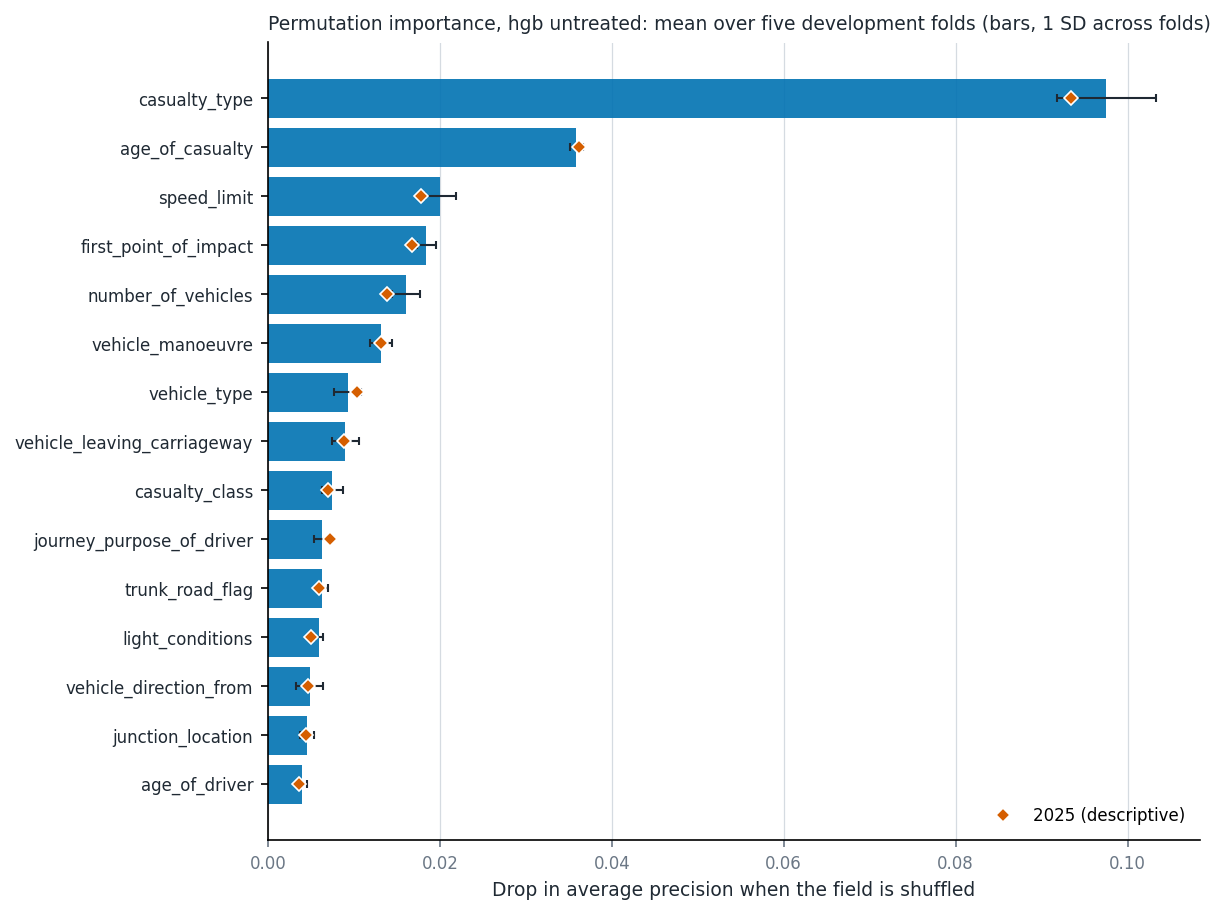

{
 "finished": "2026-11-08T02:07:53",
 "notebook": "09",
 "quick_test": false,
 "model": "hgb/untreated",
 "repeats_per_field": 3,
 "planned_repeats": 10,
 "fields": 47,
 "settings": {
  "learning_rate": 0.05,
  "max_iter": 200,
  "max_leaf_nodes": 63,
  "min_samples_leaf": 50,
  "l2_regularization": 0.0
 },
 "shuffle_seed_base": "SEED + 100 + 1000 * fold + field index",
 "checks": [
  {
   "check": "fold 0 refit vs notebook 04 scores",
   "max_abs_difference": 2.9800951040215296e-08
  },
  {
   "check": "shuffle equivalence, field age_of_casualty",
   "max_abs_difference": 0.0
  },
  {
   "check": "shuffle equivalence, field casualty_class",
   "max_abs_difference": 0.0
  },
  {
   "check": "fold 1 refit vs notebook 04 scores",
   "max_abs_difference": 2.978709168210969e-08
  },
  {
   "check": "fold 2 refit vs notebook 04 scores",
   "max_abs_difference": 2.9801759837688735e-08
  },
  {
   "check": "fold 3 refit vs notebook 04 scores",
   "max_abs_difference": 2.9794828826368303e-08


In [6]:
# 6. Figure and record ----------------------------------------------------------------------------------------------------------------------------
INK, GRID_C, MUTED, BLUE, ORANGE = '#1f2933', '#d5dbe1', '#6b7785', '#0072B2', '#D55E00'
top = summ.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8.2, 6.2), dpi=150)
yy = np.arange(len(top))
ax.barh(yy, top['mean_drop'], xerr=top['sd_across_folds'], color=BLUE, alpha=0.9, error_kw=dict(ecolor=INK, lw=1, capsize=2))
ax.plot([cmp.loc[f, 'drop_mean'] for f in top.index], yy, 'D', color=ORANGE, ms=5, mec='white', mew=0.8, label='2025 (descriptive)')
ax.set_yticks(yy); ax.set_yticklabels(top.index, fontsize=8, color=INK); ax.tick_params(axis='x', labelsize=8, colors=MUTED)
ax.set_xlabel('Drop in average precision when the field is shuffled', fontsize=9, color=INK)
for s in ('top', 'right'): ax.spines[s].set_visible(False)
ax.grid(color=GRID_C, lw=0.6, axis='x'); ax.set_axisbelow(True)
ax.set_title('Permutation importance, hgb untreated: mean over five development folds (bars, 1 SD across folds)', fontsize=9, color=INK, loc='left')
ax.legend(frameon=False, fontsize=8, loc='lower right'); fig.tight_layout(); fig.savefig(RES / 'permutation_importance_top15.png', facecolor='white'); plt.show()

summary = dict(finished=dt.datetime.now().isoformat(timespec='seconds'), notebook='09', quick_test=QUICK_TEST, model='hgb/untreated', repeats_per_field=REPEATS, planned_repeats=PLANNED_REPEATS,
               fields=len(FIELDS), settings=PARAMS, shuffle_seed_base='SEED + 100 + 1000 * fold + field index', checks=checks, mean_fold_spearman=float(agree.spearman.mean()), min_fold_spearman=float(agree.spearman.min()),
               mean_top10_overlap=float(agree.top10_overlap.mean()), top10_in_all_folds=always, top10_in_at_least_four_folds=mostly,
               spearman_dev_vs_2025=float(rho), top10_overlap_dev_vs_2025=len(dev_top & t25), refit_vs_frozen_2025_max_diff=diff)
(RES / 'permutation_importance_summary.json').write_text(json.dumps(summary, indent=1))
dep_path = FINAL / 'departures_log.json'
log = json.loads(dep_path.read_text()) if dep_path.exists() else []
if REPEATS != PLANNED_REPEATS and not QUICK_TEST and not any(d.get('id') == 'importance_repeats' for d in log):
    log.append(dict(id='importance_repeats', logged=dt.datetime.now().isoformat(timespec='seconds'), notebook='09',
                    plan='Chapter 3: ten shuffles per field.', done=f'{REPEATS} shuffles per field in each fold and on 2025.',
                    reason='Compute: one full prediction per shuffle made ten repeats take several hours on free Colab. Measured on real development data, the SD across ten shuffles for the four leading fields was 0.0009 to 0.0019 in average precision against drops of 0.020 to 0.102, and the mean of the first five shuffles differed from the mean of ten by less than 0.0007.',
                    approved_by='Recorded on 2026-11-07 after the ten-repeat run proved too slow; confirmed by running this notebook as delivered'))
    dep_path.write_text(json.dumps(log, indent=1))
print(json.dumps(summary, indent=1))
print('\nNEXT: export the results and build the Plotly dashboard (descriptive pages first, results pages after), then Chapter 4.')

In [7]:
from google.colab import drive, files
from pathlib import Path
import zipfile
drive.mount('/content/drive')
P = Path('/content/drive/MyDrive/stats19_severity')
out = Path('/content/stats19_results_for_dashboard.zip')

want = []
want += [p for p in (P/'outputs'/'results').glob('*') if p.is_file() and not p.name.startswith('bootstrap_draws')]
want += [p for p in (P/'outputs'/'features').glob('*') if p.is_file()]
want += [P/'outputs'/'models'/'final'/n for n in
         ['freeze_record.json', 'departures_log.json', 'thresholds_dev.csv', 'model_ranking_dev.csv', 'fold_macro_f1_dev.csv']]
want += [p for p in (P/'outputs'/'models').glob('*.json')] + [p for p in (P/'outputs'/'models').glob('*.csv')]
want += [P/'outputs'/'models'/'search'/n for n in ['search_summary.csv', 'selected_settings.json', 'fold_metrics_dev.csv']]

with zipfile.ZipFile(out, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in want:
        if p.exists():
            z.write(p, p.relative_to(P))
        else:
            print('missing (skipped):', p.name)
print(f'{out.stat().st_size/1e6:.1f} MB,', len(zipfile.ZipFile(out).namelist()), 'files')
files.download(str(out))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
0.5 MB, 56 files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>